# 05 — Dengue en Colombia: LightGBM vs Deep Learning más profundo (GRU, LSTM apilada, TCN)

Es el notebook 04 con **dos redes más profundas** agregadas, para responder la objeción obvia de un jurado:
*"una GRU de una sola capa es una red demasiado simple para llamarla Deep Learning"*.

| Modelo | Tipo | Qué aporta |
|---|---|---|
| Persistencia | referencia | el estado en el origen se mantiene |
| Binomial negativa local | estadístico | la mejor del informe de avance |
| LightGBM global | ML | el mejor de ML |
| GRU global (1 capa) | DL recurrente | el modelo del notebook 04, sin cambios |
| **LSTM global (2 capas)** | DL recurrente profundo | dos capas LSTM apiladas: la red recurrente "de libro" para series |
| **TCN global** | DL convolucional profundo | bloques residuales de convoluciones causales dilatadas (Bai et al., 2018) |

Todo lo demás es idéntico al 04: misma tabla, mismas particiones (ventana creciente 2016–2025), mismo presupuesto de
ajuste (**3 configuraciones por modelo**, elegidas por PR-AUC en la validación interna), pesos de clase, parada
temprana, reajuste con las mismas épocas y **promedio de 5 semillas**. Las pruebas pareadas ahora comparan cada red
contra LightGBM y contra la GRU de 1 capa, con corrección de Holm por comparaciones múltiples.

**Cómo correrlo en Colab**
1. *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Sin GPU también corre, solo más lento.
2. *Entorno de ejecución → Ejecutar todas*. Monta tu Drive y usa las mismas rutas del 04
   (`MyDrive/Datos/dengue/procesado/`). Los resultados quedan en `MyDrive/Datos/dengue/comparacion_dl_profundo/`,
   así no se pisan los del 04.
3. Para probar que todo corre antes de la corrida larga, pon `RAPIDO = True` en la celda 1 (los números de esa
   corrida no sirven para el informe).
4. **Versión semanal:** pon `FRECUENCIA = 'semanal'` en la celda 1. Necesita `casos_limpios.parquet` o los Excel
   `Datos_AAAA_210.xlsx` en tu Drive.

**Entrada:** `serie_mensual_municipios.csv` (mensual) o `casos_limpios.parquet` / Excel de SIVIGILA (semanal).

## 1. Configuración

In [1]:
import os, sys, glob, re, time, json, warnings
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    get_ipython().system('pip install -q lightgbm python-calamine')   # noqa: F821
    from google.colab import drive
    drive.mount('/content/drive')
os.environ.setdefault('KERAS_BACKEND', 'tensorflow' if IN_COLAB else 'jax')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')   # menos ruido de TensorFlow

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import lightgbm as lgb
import statsmodels.api as sm
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score, brier_score_loss
import keras
warnings.filterwarnings('ignore')

BASE    = os.environ.get('DENGUE_BASE', '/content/drive/MyDrive/Datos')
ENTRADA = os.environ.get('DENGUE_CASOS', f'{BASE}/dengue/procesado/casos_limpios.parquet')
SERIE_M = os.environ.get('DENGUE_SERIE', f'{BASE}/dengue/procesado/serie_mensual_municipios.csv')
SALIDA  = os.environ.get('DENGUE_SALIDA', f'{BASE}/dengue/comparacion_dl_profundo')

# 'mensual' (por defecto) usa serie_mensual_municipios.csv: es la versión de los resultados entregados.
# 'semanal' necesita casos_limpios.parquet (o los Excel). 'auto' = semanal si hay casos, mensual si no.
FRECUENCIA = os.environ.get('DENGUE_FRECUENCIA', 'mensual')       # ← 'semanal' para la versión por semana
RAPIDO     = os.environ.get('DENGUE_RAPIDO', '0') == '1'          # ← True = prueba corta del código, no para el informe

FECHA_MIN, FECHA_MAX = '2007-01-01', '2025-12-31'
CRITERIO_ESTABLE = 0.20     # máx. proporción de meses con <5 casos (criterio del informe de avance)
ANIOS_TEST = list(range(2016, 2026))   # ventana creciente: un pliegue por año
SEMILLAS_DL = [0, 1, 2, 3, 4]   # se suman a SEED (mismas semillas para las tres redes)
USAR_ONI = True             # si no se puede descargar, sigue sin ONI (y lo avisa)
SEED = int(os.environ.get('DENGUE_SEED', 42))
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
print('Keras backend:', keras.backend.backend(), '| RAPIDO:', RAPIDO)
if keras.backend.backend() == 'tensorflow':
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    gpus = tf.config.list_physical_devices('GPU')
    print('GPU:', gpus if gpus else 'no hay (Entorno de ejecución → Cambiar tipo → GPU T4 para ir más rápido)')

Mounted at /content/drive
Keras backend: tensorflow | RAPIDO: False
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Casos
Lo más rápido es usar `casos_limpios.parquet` del notebook 01 (un registro por caso ya limpio).
Si no existe, se leen los Excel de SIVIGILA y se aplica la limpieza del notebook 01 (misma lógica, resumida).

In [2]:
def a_fecha(serie):
    s = serie.astype(str).str.strip().str.split().str[0]
    f = pd.to_datetime(s, format='%d/%m/%Y', errors='coerce')
    for fmt in ['%Y-%m-%d', '%d-%m-%Y', '%d/%m/%y']:
        resto = f.isna()
        f[resto] = pd.to_datetime(s[resto], format=fmt, errors='coerce')
    serial = f.isna() & s.str.fullmatch(r'\d{5}(\.0)?')
    f[serial] = pd.to_datetime(s[serial].astype(float), unit='D', origin='1899-12-30')
    return f

def limpiar_desde_excel(carpeta):
    """Misma limpieza del notebook 01 (secciones 2 y 3)."""
    cols = ['CONSECUTIVE', 'COD_EVE', 'FEC_NOT', 'COD_PRE', 'COD_SUB', 'EDAD', 'SEXO', 'COD_PAIS_O',
            'COD_DPTO_O', 'COD_MUN_O', 'INI_SIN', 'TIP_CAS', 'AJUSTE', 'ANO']
    archivos = sorted(glob.glob(f'{carpeta}/**/Datos_*_210.*', recursive=True))
    assert archivos, f'No hay archivos Datos_AAAA_210 en {carpeta}'
    partes = []
    for a in archivos:
        usar = lambda c: str(c).strip().upper() in cols
        if a.lower().endswith('.csv'):
            d = pd.read_csv(a, dtype=str, usecols=usar, encoding='latin-1', sep=None, engine='python')
        else:
            try:
                d = pd.read_excel(a, dtype=str, usecols=usar, engine='calamine')
            except Exception:
                d = pd.read_excel(a, dtype=str, usecols=usar)
        d.columns = [str(c).strip().upper() for c in d.columns]
        d['ARCHIVO'] = os.path.basename(a)
        partes.append(d); print(f'  {os.path.basename(a)}: {len(d):,}')
    df = pd.concat(partes, ignore_index=True)
    for c in cols:
        if c not in df: df[c] = pd.NA
    for c in df.columns:
        df[c] = (df[c].astype('string').str.replace('\xa0', ' ').str.strip()
                 .str.replace(r'^(\d+)\.0$', r'\1', regex=True).replace('', pd.NA))
    df['fecha_sintomas'] = a_fecha(df['INI_SIN']); df['fecha_notif'] = a_fecha(df['FEC_NOT'])
    dpto, mpio = df['COD_DPTO_O'].str.zfill(2), df['COD_MUN_O'].str.zfill(3)
    df['cod_mun'] = mpio.where(mpio.str.len().eq(5).fillna(False), dpto + mpio)
    pais = df['COD_PAIS_O'].fillna('170').str.zfill(3)
    ajuste = df['AJUSTE'].fillna('0').str.upper()
    df['estado'] = df['TIP_CAS'].where(~ajuste.isin(['3', '5']), ajuste)
    df['confirmado'] = df['estado'].isin(['3', '5']).astype(int)
    df['dias_notif'] = (df['fecha_notif'] - df['fecha_sintomas']).dt.days
    pct_neg = (df['dias_notif'] < 0).groupby(df['ARCHIVO']).mean()
    corruptos = pct_neg[pct_neg > 0.05].index
    retraso = int(df.loc[~df['ARCHIVO'].isin(corruptos) & (df['dias_notif'] >= 0), 'dias_notif'].median())
    imp = df['ARCHIVO'].isin(corruptos)
    df.loc[imp, 'fecha_sintomas'] = df['fecha_notif'] - pd.Timedelta(days=retraso)
    df.loc[imp, 'dias_notif'] = retraso
    print(f'Fecha imputada (FEC_NOT − {retraso} días) en: {list(corruptos)}')
    excluir = (df['COD_EVE'].ne('210') | ajuste.isin(['6', 'D']) | ~df['estado'].isin(['2', '3', '5'])
               | pais.ne('170') | df['cod_mun'].str.startswith('01') | df['cod_mun'].isna()
               | df['fecha_sintomas'].isna() | (df['dias_notif'] < 0)
               | ~df['fecha_sintomas'].between(FECHA_MIN, FECHA_MAX)).fillna(True).astype(bool)
    df = df[~excluir]
    claves = ['CONSECUTIVE', 'COD_PRE', 'COD_SUB', 'INI_SIN', 'EDAD', 'SEXO', 'cod_mun']
    return df.drop_duplicates(subset=claves)[['cod_mun', 'fecha_sintomas', 'confirmado']]

casos = None
if os.path.exists(ENTRADA):
    casos = pd.read_parquet(ENTRADA, columns=['cod_mun', 'fecha_sintomas'])
    print('Leído', ENTRADA)
elif glob.glob(f'{BASE}/**/Datos_*_210.*', recursive=True):
    print('No está', ENTRADA, '→ se leen los Excel de', BASE)
    casos = limpiar_desde_excel(BASE)
elif os.path.exists(SERIE_M):
    print('Solo está la serie mensual:', SERIE_M)
else:
    raise FileNotFoundError(f'No encontré {ENTRADA}, ni Excel Datos_AAAA_210 en {BASE}, ni {SERIE_M}')

if casos is not None:
    casos['cod_mun'] = casos['cod_mun'].astype(str).str.zfill(5)
    casos['fecha_sintomas'] = pd.to_datetime(casos['fecha_sintomas'])
    casos = casos[casos['fecha_sintomas'].between(FECHA_MIN, FECHA_MAX)]
    print(f'{len(casos):,} casos | {casos.cod_mun.nunique():,} municipios | '
          f'{casos.fecha_sintomas.min():%Y-%m-%d} a {casos.fecha_sintomas.max():%Y-%m-%d}')

if FRECUENCIA == 'auto':
    FRECUENCIA = 'semanal' if casos is not None else 'mensual'
assert FRECUENCIA in ('semanal', 'mensual')
assert FRECUENCIA == 'mensual' or casos is not None, 'La versión semanal necesita casos_limpios.parquet o los Excel'

if casos is not None and not (FRECUENCIA == 'mensual' and os.path.exists(SERIE_M)):
    mensual = casos.assign(mes=casos['fecha_sintomas'].dt.to_period('M')).groupby(['cod_mun', 'mes']).size()
    mensual = mensual.unstack('cod_mun')
else:
    sm_ = pd.read_csv(SERIE_M, dtype={'cod_mun': str}, parse_dates=['mes'])
    sm_['cod_mun'] = sm_['cod_mun'].str.zfill(5)
    mensual = sm_.assign(mes=sm_['mes'].dt.to_period('M')).pivot_table(index='mes', columns='cod_mun',
                                                                       values='casos', aggfunc='sum')
mensual = mensual.reindex(pd.period_range(FECHA_MIN, FECHA_MAX, freq='M')).fillna(0)


if FRECUENCIA == 'semanal':
    P        = 52    # periodos por año
    H        = 8     # anticipación: la última semana observada es t-8 (~2 meses)
    VENT_OBJ = 4     # el objetivo es la suma de casos de las semanas t-3..t (≈ el "mes" t)
    L_LGB    = 12    # semanas de historia que ve LightGBM
    L_SEQ    = 26    # semanas de historia que ven las redes
    POOL     = 1     # el canal de la semana w junta w-1, w, w+1
else:
    P, H, VENT_OBJ, L_LGB, L_SEQ, POOL = 12, 2, 1, 4, 12, 0   # igual que el notebook 02: mes t con datos hasta t-2
SALIDA = f'{SALIDA}/{FRECUENCIA}'
os.makedirs(SALIDA, exist_ok=True)
print('Frecuencia:', FRECUENCIA, '| salida:', SALIDA)

Leído /content/drive/MyDrive/Datos/dengue/procesado/casos_limpios.parquet
1,700,889 casos | 1,115 municipios | 2007-01-01 a 2025-12-31
Frecuencia: mensual | salida: /content/drive/MyDrive/Datos/dengue/comparacion_dl_profundo/mensual


## 3. Serie por municipio (semanal o mensual)
**Semanal:** semana epidemiológica de domingo a sábado (calendario del INS / MMWR): la semana pertenece al año de su
miércoles; la semana 53 usa el canal de la semana 52.
**Mensual:** la misma serie del notebook 01.

En adelante `pos` es la semana (1–52) o el mes (1–12) dentro del año, y `s_obj` la variable del canal:
la suma de 4 semanas (semanal) o los casos del mes (mensual).

In [3]:
def semana_epi(fechas):
    f = pd.to_datetime(pd.Series(fechas)).reset_index(drop=True)
    domingo = f - pd.to_timedelta((f.dt.dayofweek + 1) % 7, unit='D')
    mier = domingo + pd.Timedelta(days=3)
    anio = mier.dt.year
    ene1 = pd.to_datetime(anio.astype(str) + '-01-01')
    primer_mier = ene1 + pd.to_timedelta((2 - ene1.dt.dayofweek) % 7, unit='D')
    semana = (mier - primer_mier).dt.days // 7 + 1
    return domingo.values, anio.values, semana.values

if FRECUENCIA == 'semanal':
    casos['periodo'], _, _ = semana_epi(casos['fecha_sintomas'])
    periodos = pd.date_range(casos['periodo'].min(), casos['periodo'].max(), freq='7D')
    _, anio_s, sem_s = semana_epi(periodos)
    cal = pd.DataFrame({'periodo': periodos, 'anio': anio_s, 'pos': np.minimum(sem_s, P)})
    cal['fin'] = periodos + pd.Timedelta(days=6)
    conteos = casos.groupby(['cod_mun', 'periodo']).size().unstack('cod_mun').reindex(periodos).fillna(0)
else:
    periodos = mensual.index.to_timestamp()
    cal = pd.DataFrame({'periodo': periodos, 'anio': periodos.year, 'pos': periodos.month})
    cal['fin'] = periodos + pd.offsets.MonthEnd(0)
    conteos = mensual.copy(); conteos.index = periodos
print(conteos.shape[0], 'periodos ×', conteos.shape[1], 'municipios')

228 periodos × 1115 municipios


## 4. Municipios con canal estable
Mismo criterio del informe de avance (notebook 01, sección 6): menos del 20 % de los meses con menos de 5 casos.
Se aplica sobre la serie mensual completa, igual que en el informe (ver limitaciones: es una selección con información
de todo el periodo, pero no usa la variable objetivo).

In [4]:
mensual = mensual.drop(columns=[c for c in mensual.columns if c == '00000'])   # procedencia desconocida
pct_menor5 = (mensual < 5).mean()
MUNIS = sorted(pct_menor5[pct_menor5 < CRITERIO_ESTABLE].index)
if RAPIDO: MUNIS = MUNIS[:12]
print(f'{len(MUNIS)} municipios con canal estable (<{CRITERIO_ESTABLE:.0%} de meses con <5 casos)')
conteos = conteos[MUNIS].astype(float)
s_obj = conteos.rolling(VENT_OBJ, min_periods=VENT_OBJ).sum()
conteos.sum().sort_values(ascending=False).rename('casos_total').to_frame().T

39 municipios con canal estable (<20% de meses con <5 casos)


cod_mun,76001,73001,05001,68001,50001,54001,08001,41001,13001,68276,...,41298,73449,54405,81736,54498,85010,95001,50573,73443,08433
casos_total,160693.0,57295.0,56872.0,54471.0,53370.0,49709.0,47532.0,36359.0,35422.0,29953.0,...,7246.0,6939.0,6900.0,6038.0,5715.0,5686.0,5536.0,4769.0,4694.0,4487.0


## 5. ONI (El Niño / La Niña)
Igual que en el notebook 02: cada trimestre móvil se asigna a su último mes y además se usa con un mes de rezago
(el ONI de un mes se publica a inicios del siguiente). En Colab se descarga solo; si falla, el notebook sigue sin ONI
y lo dice.

In [5]:
oni = None
if USAR_ONI:
    try:
        raw = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
        est = ['DJF','JFM','FMA','MAM','AMJ','MJJ','JJA','JAS','ASO','SON','OND','NDJ']
        ult = {s: (i + 1) % 12 + 1 for i, s in enumerate(est)}
        anio = raw['YR'] + (raw['SEAS'] == 'NDJ').astype(int)
        oni = pd.Series(raw['ANOM'].values, index=pd.PeriodIndex(
            pd.to_datetime(dict(year=anio, month=raw['SEAS'].map(ult), day=1)), freq='M'))
        oni = oni.sort_index()
        print('ONI descargado:', oni.index.min(), 'a', oni.index.max())
    except Exception as e:
        print('Sin ONI (no se pudo descargar):', type(e).__name__)
        oni = None

ONI descargado: 1950-02 a 2026-10


## 6. Canal endémico
Bortman sin años epidémicos, como en el notebook 02 (por semana epidemiológica y sobre la suma de 4 semanas en la
versión semanal):

- Referencia del año *Y*: hasta 5 años previos **no epidémicos** (mínimo 4, buscando hasta 12 atrás), sin 2020–2022.
- Año epidémico: total anual > 2 × mediana de los años anteriores.
- Umbral del periodo *w*: media geométrica + IC 95 % (t de Student) de log(s_obj + 1); en la versión semanal se juntan
  las semanas *w−1, w, w+1* de los años de referencia para que el canal no salte por ruido. *n* = número de años.
- Todo con años **anteriores** a *Y*.

Se guarda el umbral de cada año para todos los periodos. Así, para predecir un periodo del año siguiente desde
diciembre, el modelo usa el canal que ya se conocía en diciembre (sin fuga).

In [6]:
VENTANA, FACTOR_EPI, MAX_ATRAS, MIN_REF = 5, 2.0, 12, 4
ANIOS_ATIPICOS = [2020, 2021, 2022]

def canal(serie_obj, serie, cal):
    """DataFrame (año × posición 1..P) con el umbral de cada año calculado solo con años previos."""
    v = pd.DataFrame({'v': np.log1p(serie_obj.values), 'anio': cal['anio'].values, 'pos': cal['pos'].values})
    tabla = v.groupby(['anio', 'pos'])['v'].mean().unstack().reindex(columns=range(1, P + 1))
    anual = pd.Series(serie.values).groupby(cal['anio'].values).sum()
    completos = [a for a in anual.index if (cal['anio'] == a).sum() >= P - 2]
    anual = anual.loc[completos]; tabla = tabla.loc[[a for a in tabla.index if a in completos]]
    t95 = {n: stats.t.ppf(0.975, n - 1) for n in range(2, 20)}
    umbral = {}
    for Y in range(int(tabla.index.min()) + 1, int(cal['anio'].max()) + 2):
        previos = [a for a in range(Y - MAX_ATRAS, Y) if a in tabla.index and a not in ANIOS_ATIPICOS]
        epid = {a for a in previos if len(anual.loc[:a - 1]) >= 3 and anual[a] > FACTOR_EPI * anual.loc[:a - 1].median()}
        ref = [a for a in reversed(previos) if a not in epid][:VENTANA]
        if len(ref) < MIN_REF:
            continue
        x = tabla.loc[ref].values                                       # años × P
        n = len(ref)
        u = np.empty(P)
        for w in range(P):
            idx = [i for i in range(w - POOL, w + POOL + 1) if 0 <= i < P]
            vals = x[:, idx].ravel(); vals = vals[~np.isnan(vals)]
            u[w] = np.exp(vals.mean() + t95[n] * vals.std(ddof=1) / np.sqrt(n)) - 1
        umbral[Y] = u
    return pd.DataFrame(umbral).T.rename(columns=lambda c: c + 1)     # índice año, columnas 1..P

CANAL = {m: canal(s_obj[m], conteos[m], cal) for m in MUNIS}

def umbral_de(m, anios, semanas):
    c = CANAL[m]
    out = np.full(len(anios), np.nan)
    ok = np.isin(anios, c.index)
    out[ok] = c.values[c.index.get_indexer(anios[ok]), semanas[ok] - 1]
    return out

U = pd.DataFrame({m: umbral_de(m, cal['anio'].values, cal['pos'].values) for m in MUNIS}, index=periodos)
EXC = (s_obj > U).astype(float).where(U.notna() & s_obj.notna())
diag = pd.DataFrame({'pct_periodos_exceso': EXC.loc['2012':].mean(),
                     'casos_total': conteos.sum()}).sort_values('casos_total', ascending=False)
diag.to_csv(f'{SALIDA}/municipios_y_exceso.csv')
print('Proporción de periodos en exceso (2012+): mediana', round(diag.pct_periodos_exceso.median(), 2),
      '| rango', round(diag.pct_periodos_exceso.min(), 2), '-', round(diag.pct_periodos_exceso.max(), 2))
diag.head(10)

Proporción de periodos en exceso (2012+): mediana 0.33 | rango 0.16 - 0.62


,pct_periodos_exceso,casos_total
cod_mun,,
76001,0.519231,160693.0
73001,0.416667,57295.0
05001,0.279762,56872.0
68001,0.244048,54471.0
50001,0.363095,53370.0
54001,0.184524,49709.0
08001,0.327381,47532.0
41001,0.261905,36359.0
13001,0.577381,35422.0


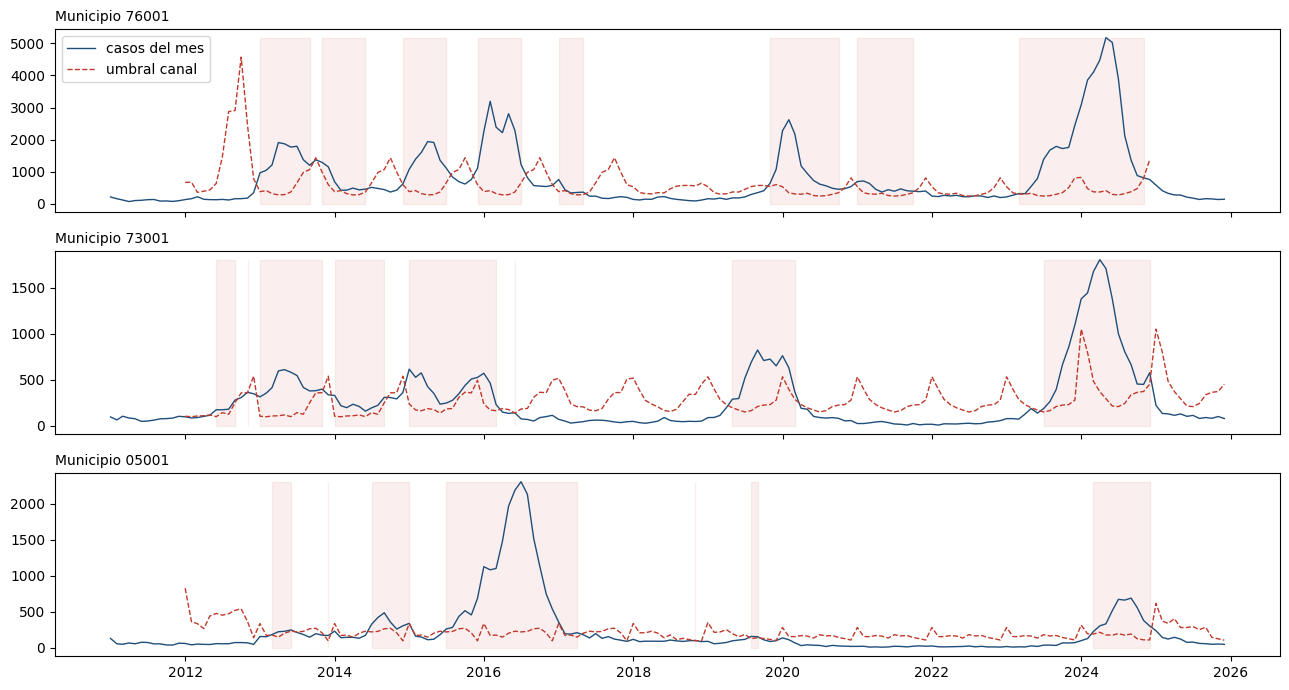

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for ax, m in zip(axes, diag.index[:3]):
    d = pd.DataFrame({'s4': s_obj[m], 'u': U[m], 'e': EXC[m]}).loc['2011':]
    ax.plot(d.index, d.s4, color='#1f4e79', lw=1, label='casos (4 semanas)' if FRECUENCIA == 'semanal' else 'casos del mes')
    ax.plot(d.index, d.u, color='#c0392b', ls='--', lw=1, label='umbral canal')
    ax.fill_between(d.index, 0, d.s4.max(), where=d.e == 1, color='#c0392b', alpha=.08, step='mid')
    ax.set_title(f'Municipio {m}', loc='left', fontsize=10)
axes[0].legend(loc='upper left'); plt.tight_layout()
plt.savefig(f'{SALIDA}/canal_ejemplos.png', dpi=120); plt.show()

## 7. Tabla de modelado (municipio × periodo objetivo)
Para el periodo objetivo *t* el **origen** es *o = t − H*: todo lo que usa el modelo se conoce en *o*.
- Semanal: objetivo = exceso de la suma de 4 semanas que termina en *t*; *H* = 8 semanas.
- Mensual: objetivo = exceso del mes *t*; *H* = 2 meses (igual que el notebook 02).

| Grupo | Variables (desde el origen hacia atrás) |
|---|---|
| Casos | log(casos + 1) de cada periodo |
| Relativo al canal | log(s_obj + 1) − log(umbral + 1) en cada periodo (cuánto está por encima o por debajo de lo normal) |
| Estado | exceso en cada periodo |
| Contexto del periodo objetivo | umbral del canal para *t* **conocido en el origen**, seno/coseno de la posición de *t* en el año |
| Clima global | ONI del mes anterior al origen (si se pudo descargar) |
| Municipio | categoría (LightGBM) / embedding (redes) |

Las tres redes reciben **exactamente las mismas entradas**: la secuencia de `L_SEQ` periodos × 5 variables, el
contexto del periodo objetivo y el municipio.

**Pliegues:** en el pliegue del año *Y* se predicen los periodos cuyo **origen** cae en *Y*, con un modelo entrenado
el 1 de enero de *Y*, o sea solo con filas cuyo objetivo terminó antes de *Y*. Validación interna para elegir
hiperparámetros y umbral: el último año de entrenamiento.

In [8]:
T = len(cal)
lc = np.log1p(conteos.values)                                     # T × M
rel = np.log1p(s_obj.values) - np.log1p(U.values)                 # T × M
exc, sv = EXC.values, s_obj.values
anio_c, pos = cal['anio'].values, cal['pos'].values
fechas, fines = cal['periodo'].values, cal['fin'].values
oni_p = (np.array([oni.get(p - 1, np.nan) for p in pd.PeriodIndex(periodos, freq='M')])
         if oni is not None else None)
L = max(L_LGB, L_SEQ)
ang = 2 * np.pi * pos / P

filas, seq = [], []
for j, m in enumerate(MUNIS):
    for t in range(L + H + 2 * VENT_OBJ, T):
        o = t - H
        y = exc[t, j]
        u_feat = umbral_de(m, np.array([anio_c[o]]), np.array([pos[t]]))[0]   # canal de t conocido en o
        if np.isnan(y) or np.isnan(u_feat):
            continue
        h = slice(o - L_SEQ + 1, o + 1)
        if np.isnan(rel[h, j]).any() or np.isnan(exc[h, j]).any():
            continue
        f = {'mun': m, 'mun_id': j, 't': t, 'o': o, 'fecha_t': fechas[t], 'fin_t': fines[t], 'anio_t': anio_c[t],
             'anio_o': anio_c[o], 'y': int(y), 'exc_o': int(exc[o, j]), 'obj_t': sv[t, j], 'umbral_feat': u_feat,
             'log_umbral_t': np.log1p(u_feat), 'sen_t': np.sin(ang[t]), 'cos_t': np.cos(ang[t])}
        for k in range(L_LGB):
            f[f'logc_{k}'] = lc[o - k, j]; f[f'rel_{k}'] = rel[o - k, j]; f[f'exc_{k}'] = exc[o - k, j]
        for k in range(3):                       # s_obj en el origen y en las 2 ventanas previas sin solaparse
            f[f'log_obj_{k}'] = np.log1p(sv[o - k * VENT_OBJ, j])
        if oni_p is not None: f['oni_o'] = oni_p[o]
        filas.append(f)
        seq.append(np.stack([lc[h, j], rel[h, j], exc[h, j], np.sin(ang[h]), np.cos(ang[h])], axis=1))
tabla = pd.DataFrame(filas)
SEQ = np.stack(seq).astype('float32')          # filas × L_SEQ × 5
tabla = tabla[tabla['anio_t'] >= 2012].copy()
SEQ = SEQ[tabla.index.values]
tabla = tabla.reset_index(drop=True)
CTX = ['log_umbral_t', 'sen_t', 'cos_t'] + (['oni_o'] if oni is not None else [])
OBJ_X = ['log_obj_0', 'log_obj_1', 'log_obj_2']
X_LGB = [f'{g}_{k}' for g in ('logc', 'rel', 'exc') for k in range(L_LGB)] + OBJ_X + CTX + ['mun_id']
print(f'{len(tabla):,} filas | {tabla.mun.nunique()} municipios | {tabla.anio_t.min()}–{tabla.anio_t.max()} | '
      f'prevalencia de exceso {tabla.y.mean():.2f} | ONI: {"sí" if oni is not None else "no"}')

6,045 filas | 39 municipios | 2012–2025 | prevalencia de exceso 0.34 | ONI: sí


## 8. Métricas y utilidades comunes
Mismas métricas del notebook 03 más el **Brier** (calidad de la probabilidad) para la prueba pareada.
`recall_inicios`: periodos en exceso que **no** estaban en exceso en el origen (la persistencia nunca acierta una).

In [9]:
GRILLA_U = np.arange(0.05, 0.96, 0.05)

def elegir_umbral(y, p):
    f = [f1_score(y, p >= u, zero_division=0) for u in GRILLA_U]
    return float(GRILLA_U[int(np.argmax(f))])

def evaluar(g, pred, prob):
    y = g['y'].values; pred = np.asarray(pred).astype(int)
    ini = (y == 1) & (g['exc_o'].values == 0)
    return {'f1': f1_score(y, pred, zero_division=0), 'pr_auc': average_precision_score(y, prob),
            'recall': recall_score(y, pred, zero_division=0), 'precision': precision_score(y, pred, zero_division=0),
            'recall_inicios': pred[ini].mean() if ini.any() else np.nan, 'n_inicios': int(ini.sum()),
            'brier': brier_score_loss(y, prob), 'n': len(y), 'positivos': int(y.sum())}

def particion(Y):
    tr = tabla[(tabla['fin_t'] < pd.Timestamp(f'{Y}-01-01')) & (tabla['anio_t'] < Y)]
    te = tabla[tabla['anio_o'] == Y]
    itr = tr[tr['anio_t'] < Y - 1]
    iva = tr[tr['anio_t'] == Y - 1]
    return tr, te, itr, iva

## 9. Modelos de referencia y ML
Mismo presupuesto de ajuste para todos: **3 configuraciones** cada uno, elegidas por PR-AUC en la validación interna.

**Persistencia**: el estado en el origen se mantiene.

**Binomial negativa local** (la mejor del informe de avance en test): una por municipio, predice `s_obj`
y da P(casos > umbral del canal conocido en el origen).

**LightGBM global** (ML): un solo modelo con todos los municipios, `mun_id` categórico, `is_unbalance`,
parada temprana en la validación interna y reajuste con el mismo número de árboles.

In [10]:
def persistencia(tr, te, itr, iva):
    return te['exc_o'].values.astype(float), 0.5, {}

NB_X = OBJ_X + ['log_umbral_t', 'sen_t', 'cos_t']

def _nb_fit_pred(g_tr, g_te):
    p = np.full(len(g_te), np.nan)
    for m, gt in g_te.groupby('mun'):
        gtr = g_tr[g_tr['mun'] == m]
        if len(gtr) < 2 * P:
            continue
        mu_x, sd_x = gtr[NB_X].mean(), gtr[NB_X].std().replace(0, 1)
        Xtr = sm.add_constant((gtr[NB_X] - mu_x) / sd_x, has_constant='add')
        Xte = sm.add_constant((gt[NB_X] - mu_x) / sd_x, has_constant='add')
        try:
            r = sm.NegativeBinomial(gtr['obj_t'].values, Xtr).fit(disp=0, maxiter=200)
            alpha = float(np.clip(r.params.iloc[-1], 1e-3, 50)); beta = r.params.iloc[:-1].values
        except Exception:
            r = sm.GLM(gtr['obj_t'].values, Xtr, family=sm.families.NegativeBinomial(alpha=1.0)).fit()
            alpha, beta = 1.0, r.params.values
        mu = np.exp(np.clip(Xte.values @ beta, -20, 20))
        n = 1 / alpha
        idx = g_te.index.get_indexer(gt.index)
        p[idx] = 1 - stats.nbinom.cdf(np.floor(gt['umbral_feat'].values), n, n / (n + mu))
    return np.nan_to_num(p, nan=0.0)

def binomial_negativa(tr, te, itr, iva):
    u = elegir_umbral(iva['y'], _nb_fit_pred(itr, iva))
    return _nb_fit_pred(tr, te), u, {}

LGB_GRID = [dict(num_leaves=7, min_child_samples=50), dict(num_leaves=15, min_child_samples=30),
            dict(num_leaves=31, min_child_samples=20)]
LGB_BASE = dict(objective='binary', learning_rate=0.03, feature_fraction=0.8, bagging_fraction=0.8,
                bagging_freq=1, lambda_l2=5.0, is_unbalance=True, verbose=-1, seed=SEED, num_threads=0)

def lightgbm_global(tr, te, itr, iva):
    mejor = None
    for g in LGB_GRID:
        prm = {**LGB_BASE, **g}
        dtr = lgb.Dataset(itr[X_LGB], itr['y'], categorical_feature=['mun_id'])
        dva = lgb.Dataset(iva[X_LGB], iva['y'], categorical_feature=['mun_id'], reference=dtr)
        b = lgb.train(prm, dtr, num_boost_round=200 if RAPIDO else 1500, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(50, verbose=False)])
        p = b.predict(iva[X_LGB], num_iteration=b.best_iteration)
        ap = average_precision_score(iva['y'], p)
        if mejor is None or ap > mejor[0]:
            mejor = (ap, prm, max(b.best_iteration, 20), p)
    _, prm, n_arb, p_val = mejor
    u = elegir_umbral(iva['y'], p_val)
    b = lgb.train(prm, lgb.Dataset(tr[X_LGB], tr['y'], categorical_feature=['mun_id']), num_boost_round=n_arb)
    return b.predict(te[X_LGB]), u, {'num_leaves': prm['num_leaves'], 'arboles': n_arb}

## 10. Modelos de Deep Learning

Las tres redes comparten la entrada, la "cabeza" (embedding del municipio de 4 dimensiones + contexto del periodo
objetivo → densa ReLU → dropout → sigmoide) y el **mismo procedimiento de entrenamiento** (`entrenar_dl`):

1. Escalado con media y desviación del entrenamiento interno.
2. Para cada una de las 3 configuraciones: Adam (1e-3), entropía cruzada con **pesos de clase balanceados**,
   lotes de 256, hasta 60 épocas con **parada temprana** (paciencia 5) en la validación interna.
3. Se elige la configuración con mejor PR-AUC en validación y el umbral que maximiza F1 ahí.
4. Se reentrena con todo el entrenamiento del pliegue el mismo número de épocas, con **5 semillas**, y se promedian
   las probabilidades.

| Red | Bloque de secuencia | Configuraciones (3) | Por qué |
|---|---|---|---|
| **GRU (1 capa)** | GRU(u) | u = 16, 32, 64 | la del notebook 04, sin cambios (sirve de control) |
| **LSTM (2 capas)** | LSTM(u, devuelve secuencia) → dropout → LSTM(u/2) → dropout | u = 32, 64, 96 | la red recurrente profunda estándar para series; la primera capa extrae patrones de corto plazo y la segunda los combina en dinámica más larga |
| **TCN** | bloques residuales de 2 convoluciones causales dilatadas (kernel 3, dilatación 1, 2, 4…) con dropout espacial | filtros = 16, 32, 64 | una familia distinta de DL: el campo receptivo cubre toda la ventana, no depende de la memoria recurrente y en la literatura de series iguala o supera a LSTM/GRU (Bai, Kolter y Koltun, 2018) |

Las convoluciones son **causales**: la salida en el periodo *k* solo ve periodos ≤ *k*, y se usa la salida del último
periodo (el origen), así que no hay fuga. Las dilataciones se eligen para que el campo receptivo cubra `L_SEQ`
(12 meses o 26 semanas).

Las LSTM/GRU usan los valores por defecto de Keras (sin `recurrent_dropout`), así TensorFlow usa cuDNN en la GPU de
Colab y entrenan rápido.

In [11]:
def _escalar(seq_tr, ctx_tr):
    ms, ss = seq_tr.reshape(-1, seq_tr.shape[-1]).mean(0), seq_tr.reshape(-1, seq_tr.shape[-1]).std(0) + 1e-6
    mc, sc = ctx_tr.mean(0), ctx_tr.std(0) + 1e-6
    return lambda s, c: ((s - ms) / ss).astype('float32'), lambda s, c: ((c - mc) / sc).astype('float32')

def _entradas_red(n_ctx):
    return keras.Input((L_SEQ, SEQ.shape[-1])), keras.Input((n_ctx,)), keras.Input((1,), dtype='int32')

def _cabeza(h, s_in, c_in, m_in, n_mun, dropout, densa=16):
    """Embedding del municipio + contexto + salida de la secuencia → densa → sigmoide (igual en las tres redes)."""
    e = keras.layers.Flatten()(keras.layers.Embedding(n_mun, 4)(m_in))
    z = keras.layers.Concatenate()([h, e, c_in])
    z = keras.layers.Dropout(dropout)(keras.layers.Dense(densa, activation='relu')(z))
    out = keras.layers.Dense(1, activation='sigmoid')(z)
    mod = keras.Model([s_in, c_in, m_in], out)
    mod.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return mod

def red_gru(cfg, n_mun, n_ctx, seed):
    """La GRU de una capa del notebook 04 (mismo orden de capas: con la misma semilla da la misma red)."""
    keras.utils.set_random_seed(seed)
    s_in, c_in, m_in = _entradas_red(n_ctx)
    h = keras.layers.GRU(cfg['unidades'])(s_in)
    return _cabeza(h, s_in, c_in, m_in, n_mun, cfg['dropout'])

def red_lstm2(cfg, n_mun, n_ctx, seed):
    """LSTM apilada de 2 capas."""
    keras.utils.set_random_seed(seed)
    s_in, c_in, m_in = _entradas_red(n_ctx)
    h = keras.layers.LSTM(cfg['unidades'], return_sequences=True)(s_in)
    h = keras.layers.Dropout(cfg['dropout'])(h)
    h = keras.layers.LSTM(cfg['unidades'] // 2)(h)
    h = keras.layers.Dropout(cfg['dropout'])(h)
    return _cabeza(h, s_in, c_in, m_in, n_mun, cfg['dropout'], densa=32)

def dilataciones_tcn(largo, kernel=3):
    """1, 2, 4, ... hasta que el campo receptivo (2 convoluciones por bloque) cubra la ventana."""
    d, campo, out = 1, 1, []
    while campo < largo:
        out.append(d); campo += 2 * (kernel - 1) * d; d *= 2
    return out

def red_tcn(cfg, n_mun, n_ctx, seed):
    """TCN: bloques residuales de convoluciones causales dilatadas."""
    keras.utils.set_random_seed(seed)
    s_in, c_in, m_in = _entradas_red(n_ctx)
    x, f = s_in, cfg['filtros']
    for d in dilataciones_tcn(L_SEQ):
        r = x
        y = keras.layers.Conv1D(f, 3, padding='causal', dilation_rate=d, activation='relu')(x)
        y = keras.layers.SpatialDropout1D(cfg['dropout'])(y)
        y = keras.layers.Conv1D(f, 3, padding='causal', dilation_rate=d, activation='relu')(y)
        y = keras.layers.SpatialDropout1D(cfg['dropout'])(y)
        if r.shape[-1] != f:
            r = keras.layers.Conv1D(f, 1)(r)                  # ajusta canales para la conexión residual
        x = keras.layers.Activation('relu')(keras.layers.Add()([y, r]))
    h = keras.layers.Flatten()(keras.layers.Cropping1D((L_SEQ - 1, 0))(x))   # salida del último periodo (el origen)
    return _cabeza(h, s_in, c_in, m_in, n_mun, cfg['dropout'], densa=32)

GRU_GRID  = [dict(unidades=16, dropout=0.2), dict(unidades=32, dropout=0.3), dict(unidades=64, dropout=0.3)]
LSTM_GRID = [dict(unidades=32, dropout=0.2), dict(unidades=64, dropout=0.3), dict(unidades=96, dropout=0.3)]
TCN_GRID  = [dict(filtros=16, dropout=0.1), dict(filtros=32, dropout=0.2), dict(filtros=64, dropout=0.2)]

def _entradas(g, fs, fc):
    s = SEQ[g.index.values]; c = g[CTX].values.astype('float32')
    return [fs(s, c), fc(s, c), g['mun_id'].values.reshape(-1, 1).astype('int32')]

def entrenar_dl(constructor, grilla):
    """Mismo procedimiento para todas las redes: 3 configuraciones, parada temprana, reajuste y promedio de semillas."""
    def ajustar(tr, te, itr, iva):
        n_mun = len(MUNIS)
        fs, fc = _escalar(SEQ[itr.index.values], itr[CTX].values)
        pos = itr['y'].mean(); cw = {0: 0.5 / (1 - pos), 1: 0.5 / pos}
        mejor = None
        for cfg in grilla:
            mod = constructor(cfg, n_mun, len(CTX), SEED)
            es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
            hist = mod.fit(_entradas(itr, fs, fc), itr['y'].values, validation_data=(_entradas(iva, fs, fc), iva['y'].values),
                           epochs=8 if RAPIDO else 60, batch_size=256, class_weight=cw, callbacks=[es], verbose=0)
            p = mod.predict(_entradas(iva, fs, fc), verbose=0, batch_size=2048).ravel()
            ap = average_precision_score(iva['y'], p)
            ep = int(np.argmin(hist.history['val_loss'])) + 1
            if mejor is None or ap > mejor[0]:
                mejor = (ap, cfg, ep, p, mod.count_params())
        _, cfg, ep, p_val, n_par = mejor
        u = elegir_umbral(iva['y'], p_val)
        fs, fc = _escalar(SEQ[tr.index.values], tr[CTX].values)
        pos = tr['y'].mean(); cw = {0: 0.5 / (1 - pos), 1: 0.5 / pos}
        probs = []
        for s in (SEMILLAS_DL[:2] if RAPIDO else SEMILLAS_DL):
            mod = constructor(cfg, n_mun, len(CTX), SEED + s)
            mod.fit(_entradas(tr, fs, fc), tr['y'].values, epochs=max(ep, 2), batch_size=256, class_weight=cw, verbose=0)
            probs.append(mod.predict(_entradas(te, fs, fc), verbose=0, batch_size=2048).ravel())
        return np.mean(probs, axis=0), u, {**cfg, 'epocas': ep, 'parametros': n_par}
    return ajustar

MODELOS_DL = {'GRU global (1 capa)': (red_gru, GRU_GRID),
              'LSTM global (2 capas)': (red_lstm2, LSTM_GRID),
              'TCN global': (red_tcn, TCN_GRID)}
MODELOS = {'Persistencia': persistencia, 'Binomial negativa local': binomial_negativa,
           'LightGBM global': lightgbm_global,
           **{n: entrenar_dl(c, g) for n, (c, g) in MODELOS_DL.items()}}
DL = list(MODELOS_DL)

# Tamaño de cada red (útil para el informe): parámetros por configuración
print('Dilataciones TCN:', dilataciones_tcn(L_SEQ))
pd.DataFrame({n: {str(cfg): c(cfg, max(len(MUNIS), 1), len(CTX), SEED).count_params() for cfg in g}
              for n, (c, g) in MODELOS_DL.items()}).T

Dilataciones TCN: [1, 2]


,"{'unidades': 16, 'dropout': 0.2}","{'unidades': 32, 'dropout': 0.3}","{'unidades': 64, 'dropout': 0.3}","{'unidades': 32, 'dropout': 0.2}","{'unidades': 96, 'dropout': 0.3}","{'filtros': 16, 'dropout': 0.1}","{'filtros': 32, 'dropout': 0.2}","{'filtros': 64, 'dropout': 0.2}"
GRU global (1 capa),1677.0,4573.0,14973.0,NaN,NaN,NaN,NaN,NaN
LSTM global (2 capas),NaN,NaN,31837.0,8989.0,69021.0,NaN,NaN,NaN
TCN global,NaN,NaN,NaN,NaN,NaN,3693.0,11517.0,40989.0


## 11. Validación con ventana creciente (2016–2025)
Un pliegue por año. Casi todo el tiempo se va en las redes; con GPU es bastante más rápido.

In [12]:
preds, info_pliegues = [], []
for Y in ANIOS_TEST:
    tr, te, itr, iva = particion(Y)
    if len(te) == 0 or iva['y'].sum() == 0:
        print(Y, 'sin datos suficientes, se omite'); continue
    t0 = time.time()
    base = te[['mun', 'anio_o', 'fecha_t', 'y', 'exc_o']].copy()
    tiempos = {}
    for nombre, fn in MODELOS.items():
        t1 = time.time()
        p, u, extra = fn(tr, te, itr, iva)
        tiempos[nombre] = round(time.time() - t1)
        base[f'p|{nombre}'] = p; base[f'u|{nombre}'] = u
        info_pliegues.append({'anio': Y, 'modelo': nombre, 'umbral': u, 'segundos': tiempos[nombre], **extra})
    preds.append(base)
    print(f'{Y}: train {len(tr):,} | test {len(te):,} ({te.y.mean():.0%} exceso) | {time.time() - t0:.0f} s', tiempos)
PR = pd.concat(preds, ignore_index=True)
PR.to_csv(f'{SALIDA}/predicciones_test.csv', index=False)
pd.DataFrame(info_pliegues).to_csv(f'{SALIDA}/hiperparametros_por_pliegue.csv', index=False)

2016: train 1,462 | test 457 (14% exceso) | 284 s {'Persistencia': 0, 'Binomial negativa local': 5, 'LightGBM global': 6, 'GRU global (1 capa)': 61, 'LSTM global (2 capas)': 43, 'TCN global': 168}
2017: train 1,918 | test 468 (4% exceso) | 237 s {'Persistencia': 0, 'Binomial negativa local': 1, 'LightGBM global': 1, 'GRU global (1 capa)': 51, 'LSTM global (2 capas)': 54, 'TCN global': 130}
2018: train 2,385 | test 468 (20% exceso) | 270 s {'Persistencia': 0, 'Binomial negativa local': 1, 'LightGBM global': 5, 'GRU global (1 capa)': 61, 'LSTM global (2 capas)': 62, 'TCN global': 141}
2019: train 2,853 | test 468 (54% exceso) | 217 s {'Persistencia': 0, 'Binomial negativa local': 1, 'LightGBM global': 1, 'GRU global (1 capa)': 43, 'LSTM global (2 capas)': 47, 'TCN global': 124}
2020: train 3,321 | test 468 (13% exceso) | 246 s {'Persistencia': 0, 'Binomial negativa local': 1, 'LightGBM global': 1, 'GRU global (1 capa)': 57, 'LSTM global (2 capas)': 54, 'TCN global': 134}
2021: train 3,78

## 12. Resultados agregados (todos los periodos de prueba 2016–2025)

In [1]:
NOMBRES = list(MODELOS)
def evaluar_modelo(g, nombre):
    p, u = g[f'p|{nombre}'].values, g[f'u|{nombre}'].values
    return evaluar(g, p >= u, p)

res = pd.DataFrame({n: evaluar_modelo(PR, n) for n in NOMBRES}).T
res_anio = pd.concat({Y: pd.DataFrame({n: evaluar_modelo(g, n) for n in NOMBRES}).T
                      for Y, g in PR.groupby('anio_o')}, names=['anio', 'modelo'])
res.round(3).to_csv(f'{SALIDA}/metricas_globales.csv'); res_anio.round(3).to_csv(f'{SALIDA}/metricas_por_anio.csv')
res[['f1', 'pr_auc', 'recall', 'precision', 'recall_inicios', 'brier', 'n_inicios']].round(3)

NameError: name 'MODELOS' is not defined

## 13. ¿La diferencia es real? Pruebas pareadas
- **Wilcoxon por municipio-año** sobre el Brier (menor es mejor) y sobre el PR-AUC (solo municipio-años con
  periodos en exceso y sin exceso).
- **Bootstrap por bloques**: se remuestrean municipio-años completos (2.000 veces) para el intervalo de la diferencia
  de F1 y PR-AUC agregados. Remuestrear bloques respeta la autocorrelación.
- **Holm**: como ahora hay varias comparaciones, los valores p de Wilcoxon se ajustan con Holm (columnas `p Holm`).
  Para concluir "gana A" usen el p ajustado.

In [13]:
def por_bloque(nombre):
    out = []
    for (m, Y), g in PR.groupby(['mun', 'anio_o']):
        p = g[f'p|{nombre}'].values; y = g['y'].values
        out.append({'mun': m, 'anio': Y, 'brier': np.mean((p - y) ** 2),
                    'pr_auc': average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan})
    return pd.DataFrame(out).set_index(['mun', 'anio'])

BLOQ = {n: por_bloque(n) for n in NOMBRES}
bloques = list(PR.groupby(['mun', 'anio_o']).indices.values())
rng = np.random.default_rng(SEED)
B = 300 if RAPIDO else 2000
muestras = [np.concatenate([bloques[i] for i in rng.integers(0, len(bloques), len(bloques))]) for _ in range(B)]

def comparar(a, b):
    da, db = BLOQ[a], BLOQ[b]
    w_br = stats.wilcoxon(da['brier'], db['brier'])
    ok = da['pr_auc'].notna() & db['pr_auc'].notna()
    w_ap = stats.wilcoxon(da.loc[ok, 'pr_auc'], db.loc[ok, 'pr_auc'])
    ya = PR['y'].values
    pa, pb = PR[f'p|{a}'].values, PR[f'p|{b}'].values
    ea, eb = (pa >= PR[f'u|{a}'].values).astype(int), (pb >= PR[f'u|{b}'].values).astype(int)
    d_f1, d_ap = [], []
    for idx in muestras:
        d_f1.append(f1_score(ya[idx], ea[idx]) - f1_score(ya[idx], eb[idx]))
        d_ap.append(average_precision_score(ya[idx], pa[idx]) - average_precision_score(ya[idx], pb[idx]))
    return {'A': a, 'B': b,
            'dif_F1 (A-B)': f1_score(ya, ea) - f1_score(ya, eb), 'IC95_F1': np.round(np.percentile(d_f1, [2.5, 97.5]), 3),
            'dif_PR-AUC (A-B)': average_precision_score(ya, pa) - average_precision_score(ya, pb),
            'IC95_PR-AUC': np.round(np.percentile(d_ap, [2.5, 97.5]), 3),
            'Brier mejor en A (% bloques)': (da['brier'] < db['brier']).mean(), 'p Wilcoxon Brier': w_br.pvalue,
            'PR-AUC mejor en A (% bloques)': (da.loc[ok, 'pr_auc'] > db.loc[ok, 'pr_auc']).mean(),
            'p Wilcoxon PR-AUC': w_ap.pvalue, 'bloques': len(da), 'bloques PR-AUC': int(ok.sum())}

def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    adj = np.minimum(np.maximum.accumulate((m - np.arange(m)) * p[o]), 1.0)
    out = np.empty(m); out[o] = adj
    return out

PROFUNDAS = [n for n in DL if n != 'GRU global (1 capa)']
pares = ([('LightGBM global', n) for n in DL]                          # la pregunta principal: ML vs cada red
         + [(n, 'GRU global (1 capa)') for n in PROFUNDAS]             # ¿la profundidad ayuda?
         + [(n, 'Binomial negativa local') for n in ['LightGBM global'] + DL]
         + [(n, 'Persistencia') for n in ['LightGBM global'] + DL])
pruebas = pd.DataFrame([comparar(a, b) for a, b in pares])
for col in ['p Wilcoxon Brier', 'p Wilcoxon PR-AUC']:
    pruebas[col.replace('Wilcoxon', 'Holm')] = holm(pruebas[col])
pruebas.to_csv(f'{SALIDA}/pruebas_pareadas.csv', index=False)
pruebas.round(4).T

NameError: name 'NOMBRES' is not defined

## 14. Figuras

In [ ]:
colores = {'Persistencia': '#9e9e9e', 'Binomial negativa local': '#e69f00', 'LightGBM global': '#0072b2',
           'GRU global (1 capa)': '#cc79a7', 'LSTM global (2 capas)': '#009e73', 'TCN global': '#d55e00'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax, met in zip(axes, ['pr_auc', 'f1']):
    for n in NOMBRES:
        s = res_anio.xs(n, level='modelo')[met]
        ax.plot(s.index, s.values, marker='o', ms=4, label=n, color=colores[n])
    ax.set_title(f'{met.upper()} por año de prueba', loc='left'); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8, loc='lower left'); plt.tight_layout()
plt.savefig(f'{SALIDA}/metricas_por_anio.png', dpi=120); plt.show()

In [ ]:
fig, axes = plt.subplots(1, len(DL), figsize=(5 * len(DL), 3.5), sharey=True)
for ax, n in zip(np.atleast_1d(axes), DL):
    d = BLOQ['LightGBM global']['brier'] - BLOQ[n]['brier']
    ax.hist(d, bins=40, color=colores[n], alpha=.8); ax.axvline(0, color='k', lw=1)
    ax.set_title(f'Brier LightGBM − Brier {n}', loc='left', fontsize=9)
fig.suptitle('Por municipio-año (negativo = gana LightGBM)', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.savefig(f'{SALIDA}/dif_brier_bloques.png', dpi=120); plt.show()

In [ ]:
m_ej = diag.index[0]
g = PR[PR['mun'] == m_ej].sort_values('fecha_t')
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.fill_between(g['fecha_t'], 0, g['y'], step='mid', color='#c0392b', alpha=.12, label='exceso real')
for n in ['Binomial negativa local', 'LightGBM global'] + DL:
    ax.plot(g['fecha_t'], g[f'p|{n}'], lw=1, label=n, color=colores[n])
ax.set_title(f'P(exceso) con {H} {"semanas" if FRECUENCIA == "semanal" else "meses"} de anticipación — municipio {m_ej}', loc='left'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig(f'{SALIDA}/probabilidades_ejemplo.png', dpi=120); plt.show()

## 15. Resumen automático

In [ ]:
def _limpio(d):
    return {k: (v.tolist() if isinstance(v, np.ndarray) else (float(v) if isinstance(v, (float, np.floating)) else v))
            for k, v in d.items()}

hip = pd.DataFrame(info_pliegues)
resumen = {
    'frecuencia': FRECUENCIA, 'rapido': RAPIDO,
    'municipios': len(MUNIS), 'filas_modelado': len(tabla), 'filas_prueba': len(PR),
    'inicios_en_prueba': int(res.loc['Persistencia', 'n_inicios']), 'oni': oni is not None,
    'metricas': res[['f1', 'pr_auc', 'recall', 'precision', 'recall_inicios', 'brier']].round(3).to_dict('index'),
    'comparaciones': [_limpio(r) for _, r in pruebas.iterrows()],
    'parametros_red_elegida_mediana': hip[hip.modelo.isin(DL)].groupby('modelo')['parametros'].median().to_dict(),
    'segundos_por_modelo': hip.groupby('modelo')['segundos'].sum().to_dict(),
}
json.dump(resumen, open(f'{SALIDA}/resumen.json', 'w'), indent=2, default=str, ensure_ascii=False)

print(f"Frecuencia {FRECUENCIA} | {len(MUNIS)} municipios | ONI: {'sí' if oni is not None else 'no'}"
      + ('  (MODO RÁPIDO: no usar para el informe)' if RAPIDO else ''))
print(res[['f1', 'pr_auc', 'brier']].round(3).to_string())
print()
for _, r in pruebas[pruebas['A'].eq('LightGBM global') & pruebas['B'].isin(DL)].iterrows():
    print(f"LightGBM − {r['B']}: dif F1 {r['dif_F1 (A-B)']:+.3f} IC95 {r['IC95_F1']} | dif PR-AUC "
          f"{r['dif_PR-AUC (A-B)']:+.3f} IC95 {r['IC95_PR-AUC']} | p Holm PR-AUC {r['p Holm PR-AUC']:.3f}")
for _, r in pruebas[pruebas['B'].eq('GRU global (1 capa)')].iterrows():
    print(f"{r['A']} − GRU 1 capa: dif PR-AUC {r['dif_PR-AUC (A-B)']:+.3f} IC95 {r['IC95_PR-AUC']} | "
          f"p Holm PR-AUC {r['p Holm PR-AUC']:.3f}")

## 16. Sensibilidad
¿El resultado depende de unos años raros o de un municipio? Se recalculan las métricas sin la pandemia
(2020–2022, subnotificación), sin 2025 (último año, con meses aún incompletos por retraso de notificación) y para
Ibagué solo en 2023–2025, que es el mismo periodo de prueba del notebook 03.

In [ ]:
def tabla_sub(g):
    return pd.DataFrame({n: evaluar_modelo(g, n) for n in NOMBRES}).T[['f1', 'pr_auc', 'recall_inicios', 'n', 'positivos', 'n_inicios']].round(3)

SUBS = {'Sin 2020–2022': PR[~PR['anio_o'].between(2020, 2022)], 'Sin 2025': PR[PR['anio_o'] < 2025],
        'Ibagué 2016–2025': PR[PR['mun'] == '73001'], 'Ibagué 2023–2025': PR[(PR['mun'] == '73001') & (PR['anio_o'] >= 2023)]}
sens = pd.concat({k: tabla_sub(g) for k, g in SUBS.items() if len(g) and g['y'].nunique() == 2}, names=['subconjunto', 'modelo'])
sens.to_csv(f'{SALIDA}/sensibilidad.csv')
for n in DL:
    gana = pd.Series({m: average_precision_score(g['y'], g[f'p|{n}']) > average_precision_score(g['y'], g['p|LightGBM global'])
                      for m, g in PR.groupby('mun') if g['y'].nunique() == 2})
    print(f'{n} tiene mejor PR-AUC que LightGBM en {gana.sum()} de {len(gana)} municipios')
sens